# Simple SPH with gravity

In this example, our main goal is to perform the simplest SPH operation: calculate the density field based on the underlying particle distribution. We assume:

- Constant smoothing length.

We also calculate pressure using the EoS, for constant internal energy of the fluid, $u$.

In [1]:
import os

import peano4
import peano4.dastgen2
import peano4.toolbox
import peano4.toolbox.particles
import dastgen2

DaStGen 2 (C) www.peano-framework.org
Peano 4 (C) www.peano-framework.org


In [2]:
# If we want to start a project from scratch, we may want to remove some of the generated code
!make clean; rm -r actions/ vertexdata/ repositories/ globaldata/ celldata/ observers/ 

project = peano4.Project( ["examples", "particles"], "sph-asymmetry-test", "." )

rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertParticlesAlongCartesianLayoutIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/CalcDensities.o ./observers/CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleAMR3.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/CalcDensities.o ./actions/Move.o ./observers/Move2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/Move2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers

## Prepare code

Peano's API does not know which settings to use on the present system. To make it copy/clone the settings identified by ./configure, we ask it to parse the generated configuration scripts. 

In [3]:
#build_mode = peano4.output.CompileMode.Asserts
build_mode = peano4.output.CompileMode.Release
project.output.makefile.parse_configure_script_outcome( "../../.." )
project.output.makefile.set_mode( build_mode )

parse configure outcome ../../../config.log to extract configure settings
found the configure call info   $ ./configure --with-mpi=mpicxx --with-multithreading=omp CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops CC=gcc CXX=g++ FC=gfortran --enable-loadbalancing --enable-exahype --enable-particles --enable-blockstructured --no-create --no-recursion

parse configure outcome ../../../src/Makefile to extract compile settings
add CXX=mpicxx
add CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops
add CXXFLAGS_PEANO_2D_ASSERTS=-DDimensions=2 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_2D_DEBUG=-DDimensions=2 -DPeanoDebug=4 -g3 -O0
add CXXFLAGS_PEANO_2D_RELEASE=-DDimensions=2 -DPeanoDebug=0
add CXXFLAGS_PEANO_2D_STATS=-DDimensions=2 -DPeanoDebug=0 -DTrackStatistics
add CXXFLAGS_PEANO_2D_TRACE=-DDimensions=2 -DPeanoDebug=1 -g3
add CXXFLAGS_PEANO_3D_ASSERTS=-DDimensions=3 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_3D_DEBUG=-DDime

## Model the particle

We create the particle through the toolbox. A particle by definition has a position, so we just need to add everything else for SPH:
- Velocity array
- Acceleration array
- Mass (constant)
- Density ($\rho\geq0$)
- Pressure ($P\geq0$)
- Internal Energy ($u\geq0$)
- SPH smoothing length ($0\leq h\leq 0.5$)


In [4]:
particle = peano4.toolbox.particles.Particle("Particle")

# Define properties
v_attr = peano4.dastgen2.Peano4DoubleArray("v","Dimensions")
a_attr = peano4.dastgen2.Peano4DoubleArray("a","Dimensions")
mass_attr    = dastgen2.attributes.Double("mass")
density_attr = dastgen2.attributes.Double("density")
pressure_attr= dastgen2.attributes.Double("pressure")
u_attr       = dastgen2.attributes.Double("u")
smoothL_attr = dastgen2.attributes.Double("smoothingLength")
Ncount_attr   = dastgen2.attributes.Integer("Ncount")
Ncount_all_attr   = dastgen2.attributes.Integer("NcountAll")

# Add particle properties
particle.data.add_attribute(v_attr)
particle.data.add_attribute(a_attr)
particle.data.add_attribute(mass_attr)
particle.data.add_attribute(density_attr)
particle.data.add_attribute(pressure_attr)
particle.data.add_attribute(u_attr)
particle.data.add_attribute(smoothL_attr)
particle.data.add_attribute(Ncount_attr)
particle.data.add_attribute(Ncount_all_attr)

particles = peano4.toolbox.particles.ParticleSet(particle)

This particle has to be added to the project. This way the project knows that we are working with this guy. We associate the particle with the vertices, as we work with the pidt (particle in dual tree) algorithm. 

In [5]:
project.datamodel.add_global_object(particle)
project.datamodel.add_vertex       (particles)

## Export global SPH constants

There are plenty of constant simulation paramaters to specify for our SPH simulation - we do that here. 

In [6]:
Dimensions = 2
project.output.makefile.set_dimension(Dimensions)

In [7]:
from numpy import pi

# We can estimate free parameter for smoothing length based on how many average ngbs we want to use
N_ngbs_mean = 10.0 # 57.9

# SPH parameters
GAMMA = str(5/3)
KERNEL_SUPPORT_RAD = "2"  # Cubic Spline = 2. Can be different in other kernels.

if(Dimensions==2):
    SMOOTH_L_FAC = str( (1.   /pi*N_ngbs_mean)**(1./2.)/float(KERNEL_SUPPORT_RAD) ) 
    CUBIC_SPLINE_SIGMA = str(10/(7*pi))
    
elif(Dimensions==3):
    SMOOTH_L_FAC = str( (3./4./pi*N_ngbs_mean)**(1./3.)/float(KERNEL_SUPPORT_RAD) ) 
    CUBIC_SPLINE_SIGMA = str(1/pi)

# parameters specific to a given problem (e.g., Sedov blast, Sod wave, ...)
BLAST_CENTER = "0.5"    # {0.5,0.5}
SPIKE_RADIUS = "0.06"
    
project.constants.export_const_with_type("GAMMA", GAMMA, "double")
project.constants.export_const_with_type("KERNEL_SUPPORT_RAD", KERNEL_SUPPORT_RAD, "double")
project.constants.export_const_with_type("SMOOTH_L_FAC"      , SMOOTH_L_FAC      , "double")
project.constants.export_const_with_type("CUBIC_SPLINE_SIGMA", CUBIC_SPLINE_SIGMA, "double")
project.constants.export_const_with_type("BLAST_CENTER", BLAST_CENTER, "double")
project.constants.export_const_with_type("SPIKE_RADIUS", SPIKE_RADIUS, "double")

## Model the setup phases

The setup remains almost unchanged. I give all particles a biased random initial velocity. This will introduce an adaptive mesh, as particles will cluster in the bottom left part of the 2d domain.

In [8]:
mesh_size = 0.2

particle_tree_analysis = peano4.toolbox.particles.ParticleTreeAnalysis(particles)
project.datamodel.add_cell(particle_tree_analysis.cell_marker)   # read docu of ParticleTreeAnalysis

create_grid = peano4.solversteps.Step( name="CreateGrid", add_user_defined_actions=False )
create_grid.add_action_set( peano4.toolbox.CreateRegularGrid(mesh_size) )
create_grid.use_vertex(particles)
create_grid.use_cell(particle_tree_analysis.cell_marker)
project.solversteps.add_step(create_grid)

## Initial conditions for particles

In [9]:
initialisation_snippet = """
   
 // Internal cutoff radious used by Peano. Should always be larger than actual SPH cutoff radious (2h).
 particle->setCutOffRadius(0.2);
 
 particle->setDensity ( 1.0 );        
 particle->setMass    ( particle->getDensity()/10/70 );       
 particle->setPressure( 1e-6);
 
// particle->setSmoothingLength( SMOOTH_L_FAC * std::pow(particle->getMass()/particle->getDensity(), 1.0/Dimensions) );
 particle->setSmoothingLength( 0.05 );

 particle->setNcount(0);
 particle->setNcountAll(0);

 particle->setU (1e-3);
 particle->setV (0, 0.0);
 particle->setV (1, 0.0);

 // Initialise the velocities
 tarch::la::Vector<Dimensions,double> blast_cent(BLAST_CENTER);
 const double dist_blast = tarch::la::norm2( particle->getX() - blast_cent );

 if ( tarch::la::smaller( dist_blast, SPIKE_RADIUS ) ){
 
   if( tarch::la::greater( particle->getX(0),0.5 ) ) {
     particle->setV (0, 1e-2);
   } else if( tarch::la::smaller( particle->getX(0),0.5 ) ){
     particle->setV (0,-1e-2);
   } else if( tarch::la::greater( particle->getX(1),0.5 ) ){
     particle->setV (1, 1e-2);
   } else if( tarch::la::smaller( particle->getX(1),0.5 ) ){
     particle->setV (1,-1e-2);
   } else{
     particle->setV (0, 0.0);
     particle->setV (1, 0.0);
   }
   
 }
 
"""

init_setup = peano4.solversteps.Step( name="Init", add_user_defined_actions=False )
init_setup.use_vertex(particles)
init_setup.use_cell(particle_tree_analysis.cell_marker)
init_setup.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
init_setup.add_action_set( peano4.toolbox.particles.InsertParticlesAlongCartesianLayoutIntoUnrefinedCells(
  particle_set=particles,
  distance_between_particles=mesh_size/4,
  initialisation_call=initialisation_snippet,
  noise=False,
  additional_includes=""" 
    #include "Constants.h" 
    """,
  computational_domain_offset=[0.0,0.0]))
init_setup.add_action_set( particle_tree_analysis )
project.solversteps.add_step(init_setup)

## Particle behaviour

We stick to exactly the same particle behaviour from a code point of view. However, we use a pre-manufactured toolbox  into which we inject the actual code. The important fact here is that we now do not simply rely on the particles of the adjacent vertices of a cell. Instead, we work with active and local particle sets.

ls: cannot access '../../python/peano4/toolbox/particles': No such file or directory


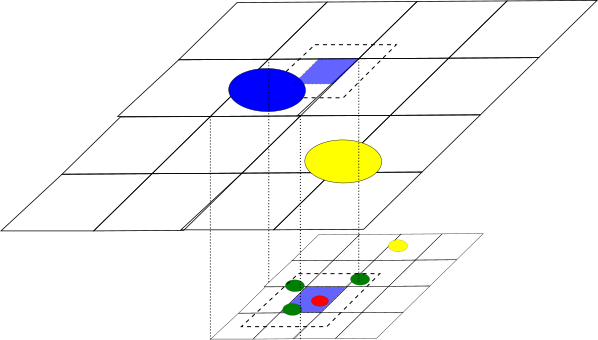

In [10]:
from IPython.display import Image
!ls ../../python/peano4/toolbox/particles
Image("../../../python/peano4/toolbox/particles/dependency_sets.png")

To understand what the individual particles in the sketch above are supposed to mean and how they are maintained and exposed to the user, please consult the documentation of the ParticleParticleInteraction class in the Python toolbox directory. It contains a lot explanations.

## Calculate densities at particles (density loop)

For each particle, we calculate the density at its position based on the positions and masses of the particles in its local neighbourhood via

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)
\end{align}
where $W$ is the smoothing kernel. 

Once the loop is done and density has been calculated, we can evaluate the fluid pressure at the particle's position using the Equation of State:

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}
Notice that, if $u$ has evolved, we should evaluate $P$ later.

In [11]:
calc_densities = peano4.solversteps.Step( "CalcDensities" )
calc_densities.use_vertex(particles)
calc_densities.use_cell(particle_tree_analysis.cell_marker)
calc_densities.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """
// The used action set does the run over the local set and the active set. So we
// simply have to feed in the particle-particle interaction potential.
 
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  const double dist = tarch::la::norm2( localParticle->getX() - activeParticle->getX() );

  const double h = localParticle->getSmoothingLength();
  const double cutoffR = 2*h;
  
  if ( tarch::la::smaller(dist, cutoffR) ) {
    const double q = dist / h;
    
    // Density calculation
    // Default SPH kernel (cubic spline)
    double W = CUBIC_SPLINE_SIGMA / std::pow( h, Dimensions );
    
    if ( tarch::la::greaterEquals(q, 2) ) {
      W *= 0;
    } else if ( tarch::la::greaterEquals(q, 1) ) {
      W *= (0.25 * (2 - q)*(2 - q)*(2 - q));
    } else {
      W *= (1 - 1.5*q*q*(1 - q/2));
    }

    // Update Density
    double densityNgbs = activeParticle->getMass() * W;
    localParticle->setDensity( localParticle-> getDensity() + densityNgbs );
    
    // Update neighbours number count if W=/=0 (i.e. when neighbour contributes with this kernel)
    if ( tarch::la::smaller(q, 2) ) {
      localParticle->setNcount( localParticle->getNcount() + 1 );
    }
    
    localParticle->setNcountAll( localParticle->getNcountAll() + 1 );

 
 }
  
"""

touch_particle_last_time_compute_kernel = """

  // Here we update the pressure with the EoS since density is done by now.
  double eosPressure = localParticle->getDensity() * localParticle->getU() * (GAMMA - 1);
  localParticle->setPressure( (eosPressure < 0) ? 0 : eosPressure );
  
"""

touch_particle_first_time_compute_kernel = """
  const double h = localParticle->getSmoothingLength();

  // Default SPH kernel (cubic spline)
  double W = CUBIC_SPLINE_SIGMA / std::pow( h, Dimensions );
  
  // we'll accumulate the data throughout mesh/particle traversal
  localParticle->setDensity ( localParticle->getMass() * W );   // particle's own contribution
  localParticle->setPressure(0.0); 
  localParticle->setNcount   (0); 
  localParticle->setNcountAll(0); 
  
"""

calc_densities.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes='#include "Constants.h" '
))
calc_densities.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_densities.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_densities)

## Move step (force loop)

In this test we use a constant velocity, hence


\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &={\bf 0}
\end{align}


## Write the actual particle movement (the move step below)

We will implement the actual particle movement ourselves. For this, we have asked Move to be an action set with manual user code, and indeed we get a Move class in the actions subdirectory once we have triggered the build process. This is, same as main, an empty blueprint. We can alter it, and Peano won't overwrite it anymore after that. If we delete it, the API will regenerate it however. The current example has already a pre-prepared Move, so it won't be empty, but you might want to delete it and regenerate it to see what you get in the first place.

Here's what I changed in the Move class: Move is a standard class which defines an action set: There's a fixed number of callbacks that are invoked by Peano, and we can use these to inject behaviour. I only alter (or plug into) three actions: 

### First access to vertex

Particles are associated to vertices. So when I hit a vertex the first time, I also hit the particles associated with it for the first time. I run over them, and set their status to NotMovedYet:


### Hit cell

When I hit a cell, I actually evaluate the "forces" and alter the particles' velocities. I do this only for the particles that reside within the cell, as I know that a neighbouring cell will either be hit after or before the current one. If I modified all particles associated with the 2^d vertices of a cell, I'd modify particles multiple times. 

Please note that I only change the particles' attributes. I do not change their position. That means, the logical topology of all data, i.e. how they are assigned to vertices remains valid and intact. This means that we don't care how Peano runs through the cells. All data remains valid.

Please see touchCellFirstTime() for details.


### Last access to vertex

When I hit a vertex for the last time, I know that all 2^d adjacent cells have been "visited". Therefore, I can now finally update the vertex position. The vertex won't be used by neighbouring cells anymore and we are fine. Again, I do this only for particles that haven't moved yet. Otherwise we might move a particle, it ends up around another vertex that we haven't processed yet and then it is moved again.

In [12]:
move_particles = peano4.solversteps.Step( "Move" )
move_particles.use_vertex(particles)
move_particles.use_cell(particle_tree_analysis.cell_marker)
move_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
move_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
  /* Given that we will use constant velocity, we do not execute any action here */
  

""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
  localParticle->setMoveState( globaldata::Particle::MoveState::NotMovedYet );

""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
  const double timeStepSize = 1e-3;
  
  if (
    localParticle->getMoveState()!=globaldata::Particle::MoveState::Moved
    and
    localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
  ) { 
  
    // Update position
    localParticle->setX( localParticle->getX() + timeStepSize * localParticle->getV() );
    
    localParticle->setMoveState( globaldata::Particle::MoveState::Moved );
  }

""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
move_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
move_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(move_particles)

### Plots setup

I will have to plot the outcome (or any snapshot). With particles, each of my dumps produces two types of files: particle data and mesh data. For the mesh, I rely on the toolbox's grid plotting. The plot is the step where we don't need the AMR criterion - the particles don't move here after all. We however run the tree analysis, so it is up-to-date for the next step.

In [13]:
# Particle plotter
particle_plotter = peano4.toolbox.particles.PlotParticlesInVTKFormat( "particles", particles, time_stamp_evaluation=peano4.toolbox.particles.PlotParticlesInVTKFormat.CountTimeSteps )
particle_plotter.add_attribute_to_plot(v_attr       , 2)
particle_plotter.add_attribute_to_plot(density_attr , 1)
particle_plotter.add_attribute_to_plot(pressure_attr, 1)
particle_plotter.add_attribute_to_plot(u_attr       , 1)
particle_plotter.add_attribute_to_plot(mass_attr    , 1)
particle_plotter.add_attribute_to_plot(smoothL_attr , 1)
particle_plotter.add_attribute_to_plot(Ncount_attr  , 1)
particle_plotter.add_attribute_to_plot(Ncount_all_attr  , 1)

# Solution plotter
print_solution = peano4.solversteps.Step( "Plot", add_user_defined_actions=False )
print_solution.use_vertex(particles)
print_solution.use_cell(particle_tree_analysis.cell_marker)
print_solution.add_action_set( particle_tree_analysis )
print_solution.add_action_set( peano4.toolbox.PlotGridInPeanoBlockFormat( filename="grid", time_stamp_evaluation=peano4.toolbox.PlotGridInPeanoBlockFormat.CountTimeSteps ) )
print_solution.add_action_set( particle_plotter )

project.solversteps.add_step(print_solution)

## Generate the actual C++ code

Next, we generate the actual Peano 4 C++ code:

In [14]:
project.generate()

generate all code ...
user has to modify class CalcDensities in actions directory manually 
user has to modify class Move in actions directory manually 
generated sph-asymmetry-test-main.cpp
write ./Makefile
./vertexdata/ParticleSet.h written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristianbarrahinojosa/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.h)
./vertexdata/ParticleSet.cpp written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristianbarrahinojosa/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.cpp)
./repositories/DataRepository.h written by TemplatedHeaderImplementationFilePair.py
./repositories/DataRepository.cpp written by TemplatedHeaderImplementationFilePair.py
././observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.h written by ActionSet.py
././observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.cpp written by ActionSet.py
write ././observers/CreateGrid.h
././observers/CreateG

## Write the main

This time, the main is slightly more sophisticated. We continue to set up the grid as before, but then we always run 10 iterations of the Move, i.e. we do 10 time steps, and then we plot. The whole sequence is repeated a couple of times. Have a look into the main file in the repo to see the whole snippet:

    ...
    for (int i=0; i<100; i++) {
      for (int j=0; j<10; j++) {
        examples::particles::observers::Move moveObserver;
        peano4::parallel::SpacetreeSet::getInstance().traverse(moveObserver);
      }
      logInfo( "main()", "plot" )
      examples::particles::observers::Plot plotTimeStepObserver;
      peano4::parallel::SpacetreeSet::getInstance().traverse(plotTimeStepObserver);
    }
    
Do not forget to include the generated header files, e.g., 
    
    //
    // =================
    // inserted manually
    // =================
    //
    #include "observers/CreateGrid.h"
    #include "observers/Init.h"
    #include "observers/Plot.h"
    #include "observers/Move.h"

## Build the code

In [15]:
project.build()

clean up project ...
rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertParticlesAlongCartesianLayoutIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/CalcDensities.o ./observers/CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleAMR3.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/CalcDensities.o ./actions/Move.o ./observers/Move2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/Move2peano4_toolbox_particles_ParticleParticleInter

## Run code

In [16]:
output_files = [ f for f in os.listdir(".") if f.endswith(".peano-patch-file") or f.endswith(".vtu") or f.endswith(".pvd") ]
for f in output_files:
  os.remove(f)

In [17]:
# success = project.run( args=["--threads", "1"], prefix=["mpirun", "-n", "1"] )
!./peano4


Peano 4 (C) www.peano-framework.org 
build: 2d, with mpi (1 ranks), omp (8 threads)
 835439945    00:00:00     rank:0       core:4       error        peano4::parallel::Node::init()                          was not able to query what the maximum tag value is (file:peano4/parallel/Node.cpp,line:92)
 841894528    00:00:00     rank:0       core:4       info         ::::main()                                              run a grid construction step and insert particles
 841954536    00:00:00     rank:0       core:0       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Refine,offset=[-2.99616e+307,-2.99616e+307],width=[8.98847e+307,8.98847e+307],h=[0.2,0.2])
 843026506    00:00:00     rank:0       core:4       info         ::::main()                                              run a grid construction step and insert particles
 843033849    00:00:00     rank:0       core:0       info         peano4::grid::Spacetree::travers

 919554663    00:00:00     rank:0       core:4       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 920167972    00:00:00     rank:0       core:3       info         ::::main()                                              run timestep
 920196609    00:00:00     rank:0       core:4       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 930565886    00:00:00     rank:0       core:4       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 931615239    00:00:00     rank:0      

 1067410978   00:00:01     rank:0       core:2       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 1067964987   00:00:01     rank:0       core:6       info         ::::main()                                              run timestep
 1068018903   00:00:01     rank:0       core:2       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 1076812841   00:00:01     rank:0       core:2       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 1077270243   00:00:01     rank:0      

 1231688424   00:00:01     rank:0       core:1       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 1232612128   00:00:01     rank:0       core:1       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 1238736339   00:00:01     rank:0       core:1       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 1239236445   00:00:01     rank:0       core:3       info         ::::main()                                              run timestep
 1239248035   00:00:01     rank:0      

 1374586654   00:00:01     rank:0       core:6       info         ::::main()                                              run timestep
 1374602253   00:00:01     rank:0       core:1       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 1384302437   00:00:01     rank:0       core:1       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 1384944937   00:00:01     rank:0       core:5       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 1392615750   00:00:01     rank:0       core:5       info         examp

 1539514678   00:00:01     rank:0       core:1       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 1540355959   00:00:01     rank:0       core:1       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 1548395632   00:00:01     rank:0       core:1       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 1548943765   00:00:01     rank:0       core:6       info         ::::main()                                              run timestep
 1548953479   00:00:01     rank:0      

... (77 outputs left out)

 13668551746  00:00:13     rank:0       core:7       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 13669119235  00:00:13     rank:0       core:3       info         ::::main()                                              run timestep
 13669151665  00:00:13     rank:0       core:0       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 13678560127  00:00:13     rank:0       core:0       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 13679244011  00:00:13     rank:0      

 13819693685  00:00:13     rank:0       core:4       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 13820378138  00:00:13     rank:0       core:6       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 13827982667  00:00:13     rank:0       core:6       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 13828564886  00:00:13     rank:0       core:3       info         ::::main()                                              plot        
 13839969300  00:00:13     rank:0      

 13973960513  00:00:13     rank:0       core:5       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 13974642935  00:00:13     rank:0       core:5       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 13982639724  00:00:13     rank:0       core:5       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 13983226338  00:00:13     rank:0       core:3       info         ::::main()                                              run timestep
 13983249186  00:00:13     rank:0      

 14132780228  00:00:14     rank:0       core:4       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 14133426547  00:00:14     rank:0       core:7       info         ::::main()                                              run timestep
 14133460673  00:00:14     rank:0       core:6       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Erase,offset=[0.888889,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111])
 14144628259  00:00:14     rank:0       core:6       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/1369/400/0/0/0 on tree 0
 14145203418  00:00:14     rank:0      

# Summary of SPH equations
For these, we follow the review paper by Price et al (2018).

Notice that, throughout this, $h$ denotes the smoothing length.

#### SPH basics

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)\\
\Omega_a &= 1 - \frac{\partial h_a}{\partial \rho_a}\sum_b m_b\frac{\partial W_{ab}(h_a)}{\partial h_a} \qquad\qquad (\Omega_a=1 \quad \textrm{for constant $h$})
\end{align}

#### Further fluid properties

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}



#### Euler equation (w/o artificial viscosity terms)

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm grav}_a + {\bf a}^{\rm others}_a\\
\end{align}


#### Evolution of internal energy:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}m_b\sum_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)\\
\end{align}


#### Useful relations

\begin{align}
\nabla_aW_{ab}&=\frac{C_{\rm norm}}{h^4}f'(q)\hat{{\bf r}}_{ab} \\
\frac{\partial W_{ab}}{\partial h}(r,h)&=-\frac{C_{\rm norm}}{h^4}[3f(q)+qf'(q)] \\
\frac{\partial h_a}{\partial \rho_a} &= -\frac{3h_a}{\rho_a} \\
\end{align}